In [1]:
import os

api_key = os.getenv("AICREDITS_API_KEY")
base_url = os.getenv("AICREDITS_BASE_URL")

In [2]:
from langchain_openai import ChatOpenAI

llm_small = ChatOpenAI(model="deepseek/deepseek-chat-v3.1", 
                       api_key=api_key,
                      base_url=base_url,temperature=1.0)

In [3]:
llm_small.invoke("Hi, how are you?").content

"Hi! I'm doing well, thank you for asking! 😊 How are you today?"

In [4]:
from datasets import load_dataset
ds = load_dataset("cais/mmlu", "high_school_geography")

i = 6
ds_dict = ds["test"].take(100).to_dict()
question = ds_dict["question"][i]
options = "\n".join([f"{i}. {a}" for i, a in enumerate(ds_dict["choices"][i])])

In [5]:
print(question)

Which of the following countries does NOT have a well-known example of a relict boundary?


In [6]:
print(options)

0. Vietnam
1. United Kingdom
2. Germany
3. Bolivia


In [8]:
llm_small.invoke("what is the meaning of relict boundary with respect to a country?").content

'Of course. This is an excellent question in political geography.\n\nA **relict boundary** is a former political boundary that no longer functions as an international border but whose presence is still evident in the cultural landscape. It is a boundary that has been **retired** or rendered obsolete, typically due to political changes like war, dissolution of a country, or unification.\n\nThink of it as a **political ghost** or a **scar on the landscape**. The line on the map is gone, but its after-effects and physical traces linger.\n\n### Key Characteristics of a Relict Boundary:\n\n1.  **No Longer an International Border:** The key defining feature is that it is no longer an active, legally recognized boundary between sovereign states.\n2.  **Cultural and Physical Evidence:** Its existence continues to influence human geography. This evidence can be:\n    *   **Cultural:** Differences in language, religion, dialect, or local laws on either side of the former line.\n    *   **Economi

Building our Research Agent

In [9]:
from langchain_community.agent_toolkits.load_tools import load_tools
from langgraph.prebuilt import create_react_agent
from langchain_tavily import TavilySearch


os.environ["TAVILY_API_KEY"] = "" #put your tavily key here

#llm = ChatOpenAI(model = "google/gemini-2.5-flash", api_key=api_key, base_url=base_url)

other_tools = load_tools(
    tool_names=["ddg-search", "arxiv", "wikipedia"],
    llm=llm_small
)

tavily_tool = TavilySearch(max_results=3)

research_tools = [tavily_tool] + other_tools

system_prompt = (
    "You're a hard-working, curious and creative student. "
    "You're working on exam quesion. Think step by step."
    "Always provide an argumentation for your answer. "
    "Do not assume anything, use available tools to search "
    "for evidence and supporting statements."
)

research_agent = create_react_agent(model=llm_small, tools=research_tools, prompt=system_prompt)

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_17244\1906157848.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.agent_toolkits.load_tools import load_tools
C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_17244\1906157848.py:27: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(model=llm_small, tools=research_tools, prompt=system_prompt)


Let us give a reflection prompt

In [10]:
reflection_prompt = (
    "You are a university professor and you're supervising a student who is "
    "working on multiple-choice exam question. "
    "Given the dialogue above, reflect on the answer provided and give a feedback "
    " if needed. If you think the final answer is correct, reply with "
    "an empty message. Only provide critique if you think the last answer might "
    "be incorrect or there are reasoning flaws. Do not assume anything, "
    "evaluate only the reasoning the student provided and whether there is "
    "enough evidence for their answer."
)

Putting everything together

In [12]:
from langchain_core.prompts import PromptTemplate
from langgraph.types import Command
from langchain_core.runnables import RunnableConfig
from langgraph.graph import StateGraph, START, END, MessagesState

question_template = PromptTemplate.from_template(
    "QUESTION:\n{question}\n\nANSWER OPTIONS:\n{options}\n\n"
)

def _ask_question(state):
    return {"messages": [("human", question_template.invoke(state).text)]}

def _give_feedback(state, config: RunnableConfig):
    messages = event["messages"] + [("human", reflection_prompt)]
    max_messages = config["configurable"].get("max_messages", 20)

    if len(messages) > max_messages:
        return Command(update = {}, goto=END)

    result = llm_small.invoke(messages)
    if result.content:
        return Command(
            update = {"messages":[("assistant", result.content),
                                 ("human", "Please, address the feedback above and give an answer.")]},
            goto = "research"
        )

    return Command(update = {}, goto =END)  

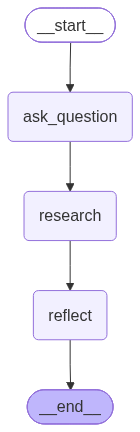

In [13]:
from langgraph.graph import START, END, StateGraph, MessagesState

class ReflectionAgentState(MessagesState):
    question: str
    options: str

builder = StateGraph(ReflectionAgentState)
builder.add_node("ask_question", _ask_question)
builder.add_node("research", research_agent)
builder.add_node("reflect", _give_feedback)

builder.add_edge(START, "ask_question")
builder.add_edge("ask_question", "research")
builder.add_edge("research", "reflect")
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
async for _, event in graph.astream({"question": question, "options": options}, stream_mode=["values"]):
  print(len(event["messages"]))

0
1
18
20


OpenAIAPIError: Internal Server Error

In [15]:
for m in event["messages"]:
  print(type(m))

<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>


In [16]:
for m in event["messages"]:
    m.pretty_print()

================================ Human Message =================================

QUESTION:
Which of the following countries does NOT have a well-known example of a relict boundary?

ANSWER OPTIONS:
0. Vietnam
1. United Kingdom
2. Germany
3. Bolivia


================================== Ai Message ==================================

I need to understand what a "relict boundary" is and then examine each country to see which one doesn't have a well-known example. Let me search for information about relict boundaries.
Tool Calls:
  tavily_search (call_1ddd)
 Call ID: call_1ddd
  Args:
    query: relict boundary definition geography examples
================================= Tool Message =================================
Name: tavily_search

{"query": "relict boundary definition geography examples", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://helpfulprofessor.com/relic-boundary-examples", "title": "13 Examples of Relic Boundaries (Human Geography 

test 2

In [21]:
question = "Which film won the Academy Award for Best Picture at the 94th Academy Awards held in 2022?"

options = "\n".join([
    "0. Belfast",
    "1. CODA",
    "2. Dune",
    "3. The Power of the Dog"
])

In [22]:
async for _, event in graph.astream({"question": question, "options": options}, stream_mode=["values"]):
    print(len(event["messages"]))

0
1
4
6
7
9
10
12
13
15
16
18
19
21


OpenAIAPIError: Internal Server Error

In [23]:
for m in event["messages"]:
  print(type(m))

<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.tool.ToolMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.human.HumanMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_core.messages.ai.AIMessage'>
<class 'langchain_co

In [24]:
for m in event["messages"]:
    m.pretty_print()

================================ Human Message =================================

QUESTION:
Which film won the Academy Award for Best Picture at the 94th Academy Awards held in 2022?

ANSWER OPTIONS:
0. Belfast
1. CODA
2. Dune
3. The Power of the Dog


================================== Ai Message ==================================

I'll search for information about the 94th Academy Awards to determine which film won Best Picture in 2022.
Tool Calls:
  tavily_search (call_137e)
 Call ID: call_137e
  Args:
    query: 94th Academy Awards Best Picture winner 2022
    search_depth: basic
================================= Tool Message =================================
Name: tavily_search

{"query": "94th Academy Awards Best Picture winner 2022", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://abcnews.com/Entertainment/live-updates?id=83623623", "title": "Oscars 2022 recap: 'CODA' wins best picture, Will Smith wins best actor after Chris Rock confronta